In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils, base

ERROR:2025-12-10 13:10:43,850:jax._src.xla_bridge:487: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/home/fangxu/.pyenv/versions/jax-cuda12/lib/python3.11/site-packages/jax/_src/xla_bridge.py", line 485, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/fangxu/.pyenv/versions/jax-cuda12/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/home/fangxu/.pyenv/versions/jax-cuda12/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 285, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE


In [15]:
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

# beta=13.48 # non-int params1
# b = 2.0
# bk =  5.5

beta=13.4492 # int params1
b = 2.0
bk =  5.5

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=4, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_wLens_record(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [16]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=50,
            bs=jnp.array([b])
        ) 

In [ ]:
# wlens_array = my_driver.steady_record.flatten()
# np.save("../data/wLens_distribution/int_params1.npy", wlens_array)

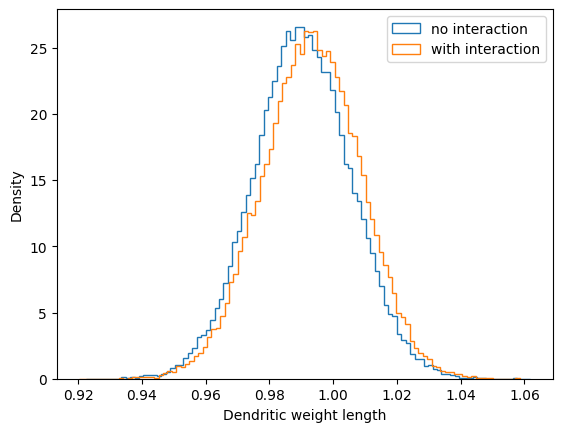

In [3]:
wlens_array_nonInt = np.load("../data/fixed_params/wLens_distribution/nonInt_params1.npy")
wlens_array_int = np.load("../data/fixed_params/wLens_distribution/int_params1.npy")

plt.hist(wlens_array_nonInt, bins=100, density=True, histtype="step", label="no interaction");
plt.hist(wlens_array_int, bins=100, density=True, histtype="step", label="with interaction");
plt.xlabel("Dendritic weight length");
plt.ylabel("Density");
plt.legend();

# plt.savefig("../figures/wLen_distribution_params1.png")

In [4]:
wlens_array_int.shape

(60000,)